# Exploring Hacker News with SQL

Goal: Use SQL on Google BigQuery to describe how Hacker News is used: which types of items are posted, who posts the most, how scores are distributed, how activity changes over the years, weekdays and hours, and how the share of AI-related story titles has changed.

Dataset: bigquery-public-data.hacker_news.full, with 50,098,998 items from 9 October 2006 to 17 October 2026. Each row is a story, comment, job, poll or poll option.

Tools: Google BigQuery SQL, with Python (pandas, matplotlib, seaborn) for charts.

Conventions: All times are in UTC. Questions 2 to 7 exclude dead items, and Question 1 counts every item.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.cloud import bigquery

client = bigquery.Client()
sns.set_theme(style="whitegrid")

def run(sql):
    return client.query(sql).to_dataframe()

Using Kaggle's public dataset BigQuery integration.


In [2]:
audit = run("""
SELECT COUNT(*) AS total_rows,
       COUNT(DISTINCT id) AS distinct_ids,
       COUNTIF(timestamp IS NULL) AS missing_timestamp,
       COUNTIF(type IS NULL) AS missing_type,
       COUNTIF(dead) AS dead_items,
       COUNTIF(deleted) AS deleted_items,
       MIN(timestamp) AS earliest,
       MAX(timestamp) AS latest
FROM `bigquery-public-data.hacker_news.full`
""")
audit.T

,0
total_rows,50098998
distinct_ids,50098998
missing_timestamp,26722
missing_type,0
dead_items,2255708
deleted_items,0
earliest,2006-10-09 18:21:51+00:00
latest,2026-10-17 09:12:48+00:00


## Data quality audit

Size and uniqueness: The table has 50,098,998 items and every id is unique, so there are no duplicate rows.

Date range: Items run from 9 October 2006 to 17 October 2026 (UTC), so 2026 and the month of October 2026 are partial.

Missing values: No item is missing its type. 26,722 items (about 0.05%) have no timestamp, so they are left out of the time-based questions.

Dead and deleted items: 2,255,708 items (about 4.5%) are flagged as dead. They are excluded from Questions 2 to 7. No item is flagged as deleted, so the deleted filter in those queries removes nothing. Question 1 counts all items, including dead ones.

In [3]:
# Business Question 1: What types of posts are published on Hacker News?

query = """
SELECT 
    type,
    COUNT(*) AS total_posts,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 2) AS percentage
FROM 
    `bigquery-public-data.hacker_news.full`
WHERE 
    type IS NOT NULL
GROUP BY 
    type
ORDER BY 
    total_posts DESC;
"""

df = run(query)
df

,type,total_posts,percentage
0,comment,43717584,87.26
1,story,6345036,12.66
2,job,18223,0.04
3,pollopt,15890,0.03
4,poll,2265,0.00


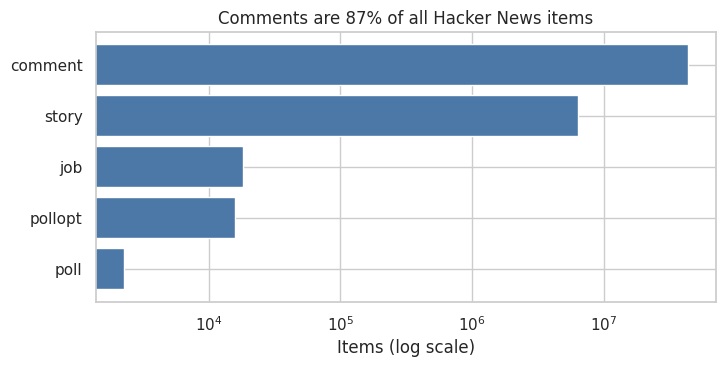

In [4]:
plt.figure(figsize=(8, 3.5))
plt.barh(df["type"], df["total_posts"], color="#4C78A8")
plt.xscale("log"); plt.gca().invert_yaxis()
plt.xlabel("Items (log scale)")
plt.title("Comments are 87% of all Hacker News items")
plt.show()

Business Question 1: What types of posts are published on Hacker News?

Interpretation & Key Findings

Comments dominate the platform: Comments are 87.26% of all items, so discussion is the core activity on the site.

Stories are the second-largest category: Stories make up 12.66% of items and are the main links and articles being discussed.

Other item types are rare: Jobs, polls and poll options together are under 0.1% of items.

Note: Counts include all items, including about 4.5% flagged as dead.

In [5]:
# Business Question 2: Who are the most active contributors on Hacker News?

query_2 = """
SELECT `by` AS author,
       COUNTIF(type = 'comment') AS comments,
       COUNTIF(type = 'story') AS stories,
       COUNT(*) AS total,
       EXTRACT(YEAR FROM MIN(timestamp)) AS first_year,
       EXTRACT(YEAR FROM MAX(timestamp)) AS last_year
FROM `bigquery-public-data.hacker_news.full`
WHERE `by` IS NOT NULL AND dead IS NOT TRUE AND deleted IS NOT TRUE
GROUP BY author
ORDER BY total DESC
LIMIT 10
"""

df_2 = run(query_2)
df_2

,author,comments,stories,total,first_year,last_year
0,dang,80820,227,81070,2014,2026
1,pjmlp,73673,2987,76660,2010,2026
2,tptacek,74182,451,74646,2007,2026
3,jacquesm,63627,2403,66329,2008,2026
4,rbanffy,25702,37001,62715,2008,2026
5,dragonwriter,58563,15,58578,2012,2026
6,JumpCrisscross,37106,9857,46963,2011,2026
7,PaulHoule,26372,19419,45791,2010,2026
8,toomuchtodo,38818,2620,41438,2011,2026
9,coldtea,39540,136,39676,2013,2026


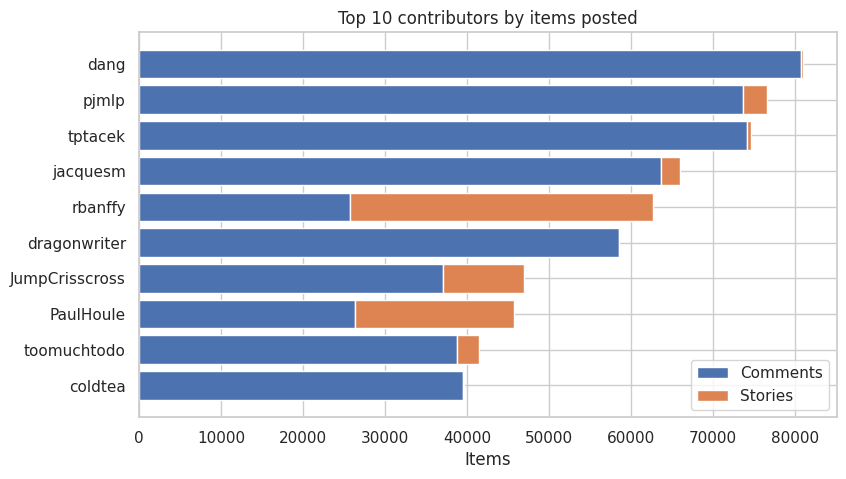

In [6]:
d = df_2.sort_values("total")
plt.figure(figsize=(9, 5))
plt.barh(d["author"], d["comments"], label="Comments")
plt.barh(d["author"], d["stories"], left=d["comments"], label="Stories")
plt.legend()
plt.xlabel("Items")
plt.title("Top 10 contributors by items posted")
plt.show()

Business Question 2: Who are the most active contributors on Hacker News?

Interpretation & Key Findings

Most active account: dang has posted 81,070 items, about 4,400 more than the second-ranked account, pjmlp (76,660). Dang is the site’s moderator, so his activity partly reflects that role.

Mostly commenters: Nine of the top 10 accounts have more comments than stories. Dragonwriter has only 15 stories and dang only 227.

The exceptions: Rbanffy is the only account in the top 10 with more stories (37,001) than comments (25,702). PaulHoule also submits heavily, with 19,419 stories, but still posts more comments (26,372).

Long-term activity: The top 10 accounts first posted between 2007 and 2014, and every one of them is still active in 2026.

Small share of the site: Together the top 10 accounts account for about 594,000 items, roughly 1.2% of all items, so even the heaviest users are a small part of the site’s total activity.

Note: Counts cover items by registered accounts and exclude dead and deleted items.

In [7]:
share = 100 * df_2["total"].sum() / df["total_posts"].sum()
print(f"Top 10 share of all items: {share:.2f}%")

Top 10 share of all items: 1.19%


In [8]:
# Business Question 3:  How are scores distributed across stories and jobs?

query_3 = """
SELECT type,
       COUNT(*) AS items,
       APPROX_QUANTILES(score, 100)[OFFSET(50)] AS median_score,
       APPROX_QUANTILES(score, 100)[OFFSET(90)] AS p90_score,
       APPROX_QUANTILES(score, 100)[OFFSET(99)] AS p99_score,
       ROUND(AVG(score), 2) AS avg_score,
       MAX(score) AS max_score,
       ROUND(100 * COUNTIF(score <= 1) / COUNT(*), 1) AS pct_score_le_1
FROM `bigquery-public-data.hacker_news.full`
WHERE score IS NOT NULL
  AND type IN ('story', 'job')
  AND dead IS NOT TRUE AND deleted IS NOT TRUE
GROUP BY type
"""

df_3 = run(query_3)
df_3

,type,items,median_score,p90_score,p99_score,avg_score,max_score,pct_score_le_1
0,job,17414,1,1,23,1.64,220,96.8
1,story,4802225,2,28,296,16.96,6015,31.8


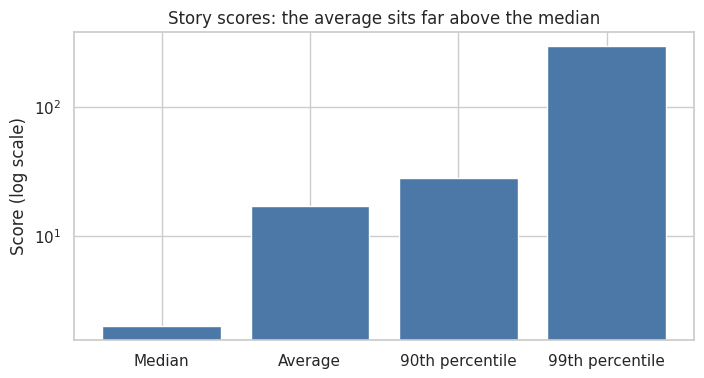

In [9]:
s = df_3[df_3["type"] == "story"].iloc[0]
labels = ["Median", "Average", "90th percentile", "99th percentile"]
values = [s["median_score"], s["avg_score"], s["p90_score"], s["p99_score"]]

plt.figure(figsize=(8, 4))
plt.bar(labels, values, color="#4C78A8")
plt.yscale("log")
plt.ylabel("Score (log scale)")
plt.title("Story scores: the average sits far above the median")
plt.show()

Business Question 3: How are scores distributed across stories and jobs?

Interpretation & Key Findings

Typical story score: The median story score is 2, but the average is 16.96, about 8 times higher. A small number of very popular stories pull the average far above what a typical story receives, which is why the median is the better measure of a typical story.

Most stories get little attention: 31.8% of stories have a score of 1 or less. The top 10% of stories score 28 or more, and the top 1% score about 296 or more.

The most popular story: The highest-scoring story has a score of 6,015.

Jobs: Job posts have a median score of 1 and an average of 1.64, and 96.8% of them have a score of 1 or less. Even the best job post (220) scores far below the best story.

Note: Comments have no score in this dataset, so they are excluded. Polls and poll options are also excluded because their scores work differently. Only stories and jobs with a score are counted (about 4.8 million stories), and dead and deleted items are excluded. Percentiles are approximate.

In [10]:
# Business Question 4: How has posting activity changed over the years?

query_4 = """
WITH yearly AS (
  SELECT EXTRACT(YEAR FROM timestamp) AS year,
         COUNTIF(type = 'story') AS stories,
         COUNTIF(type = 'comment') AS comments,
         COUNT(*) AS total
  FROM `bigquery-public-data.hacker_news.full`
  WHERE timestamp IS NOT NULL AND dead IS NOT TRUE AND deleted IS NOT TRUE
  GROUP BY year
)
SELECT *,
       ROUND(100 * (total - LAG(total) OVER (ORDER BY year))
             / LAG(total) OVER (ORDER BY year), 1) AS yoy_pct
FROM yearly
ORDER BY year
"""

df_4 = run(query_4)
df_4

,year,stories,comments,total,yoy_pct
0,2006,46,12,58,NaN
1,2007,22020,70065,92116,158720.7
2,2008,63398,246570,310690,237.3
3,2009,91303,485228,578417,86.2
4,2010,147459,834733,983642,70.1
5,2011,209360,1029445,1242284,26.3
6,2012,246266,1226480,1474810,18.7
7,2013,277985,1645984,1927422,30.7
8,2014,263288,1496233,1762919,-8.5
9,2015,275628,1600372,1878951,6.6


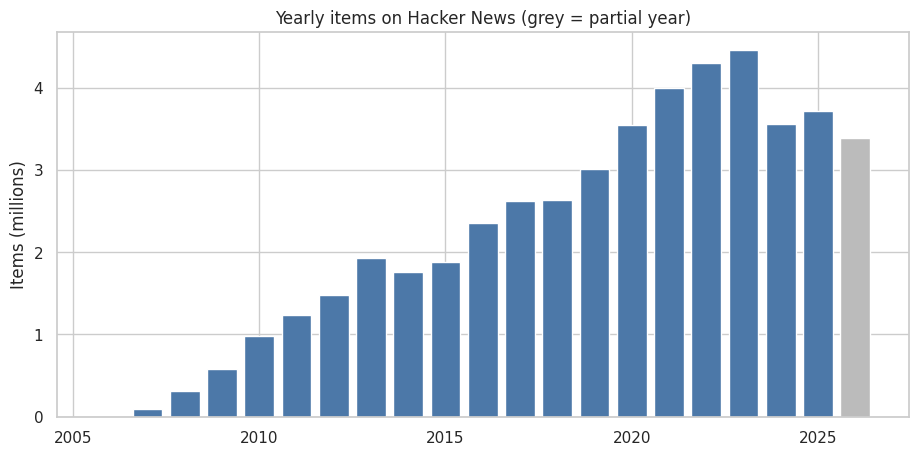

In [11]:
cur = pd.Timestamp.now().year
colors = ["#BBBBBB" if y == cur else "#4C78A8" for y in df_4["year"]]
plt.figure(figsize=(11, 5))
plt.bar(df_4["year"], df_4["total"] / 1e6, color=colors)
plt.ylabel("Items (millions)")
plt.title("Yearly items on Hacker News (grey = partial year)")
plt.show()

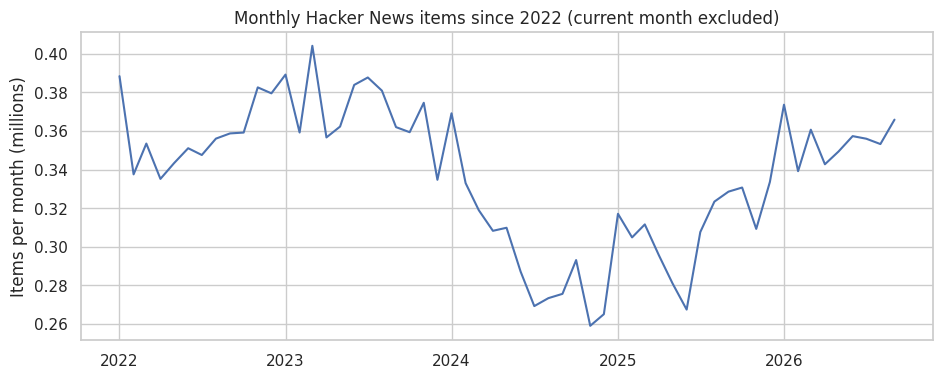

In [12]:
df_m = run("""
SELECT DATE_TRUNC(DATE(timestamp), MONTH) AS month, COUNT(*) AS items
FROM `bigquery-public-data.hacker_news.full`
WHERE timestamp >= TIMESTAMP('2022-01-01') AND dead IS NOT TRUE AND deleted IS NOT TRUE
GROUP BY month ORDER BY month
""")
plt.figure(figsize=(11, 4))
plt.plot(df_m["month"].iloc[:-1], df_m["items"].iloc[:-1] / 1e6)
plt.ylabel("Items per month (millions)")
plt.title("Monthly Hacker News items since 2022 (current month excluded)")
plt.show()

Business Question 4: How has posting activity changed over the years?

Interpretation & Key Findings

Fast early growth: Yearly items grew from 92,116 in 2007 to 983,642 in 2010, more than tenfold in three years. Growth then slowed, ranging from -8.5% to +30.7% a year between 2011 and 2023, and falling to 7.5% in 2022 and 3.8% in 2023.

Peak in 2023: Activity peaked at about 4.45 million items in 2023.

A decline through 2024: Items fell 20.1% in 2024, to about 3.56 million. Most of the fall came from comments (down 21.2%, from 4.13 million to 3.25 million), while stories fell 6.1% (from 325,090 to 305,195). The monthly chart shows a gradual decline from early 2024 to a low of about 0.26 million items a month around the end of 2024, not a single sudden drop. This data cannot explain why.

Recovery: 2025 rose 4.2% to about 3.71 million, still about 17% below the 2023 peak. In 2026 monthly volume has returned to roughly 0.34 to 0.37 million items, a little below the 2022 to 2023 range of about 0.34 to 0.40 million.

Comments drive the growth: Story submissions have stayed between about 263,000 and 354,000 a year since 2013, while comments grew about 2.5 times, from 1.65 million in 2013 to 4.13 million in 2023.

Note: 2026 is a partial year (3.39 million items so far) and is shown in grey in the yearly chart and left out of the comparisons. The latest month is excluded from the monthly chart because it is incomplete. Counts exclude dead and deleted items. The very high growth rates in 2007 to 2009 reflect a tiny starting base.

In [13]:
# Business Question 5: Which day of the week has the highest activity?

query_5 = """
SELECT EXTRACT(DAYOFWEEK FROM timestamp) AS day_of_week,
       COUNT(*) AS total_posts
FROM `bigquery-public-data.hacker_news.full`
WHERE timestamp IS NOT NULL AND dead IS NOT TRUE AND deleted IS NOT TRUE
GROUP BY day_of_week
ORDER BY day_of_week
"""

df_5 = run(query_5)
day_map = {1: 'Sunday', 2: 'Monday', 3: 'Tuesday', 4: 'Wednesday',
           5: 'Thursday', 6: 'Friday', 7: 'Saturday'}
df_5['day_name'] = df_5['day_of_week'].map(day_map)
df_5['pct_of_total'] = (100 * df_5['total_posts'] / df_5['total_posts'].sum()).round(1)
df_5[['day_name', 'total_posts', 'pct_of_total']]

,day_name,total_posts,pct_of_total
0,Sunday,5132343,10.7
1,Monday,7303809,15.3
2,Tuesday,7766744,16.2
3,Wednesday,7755394,16.2
4,Thursday,7622031,15.9
5,Friday,7189190,15.0
6,Saturday,5047057,10.6


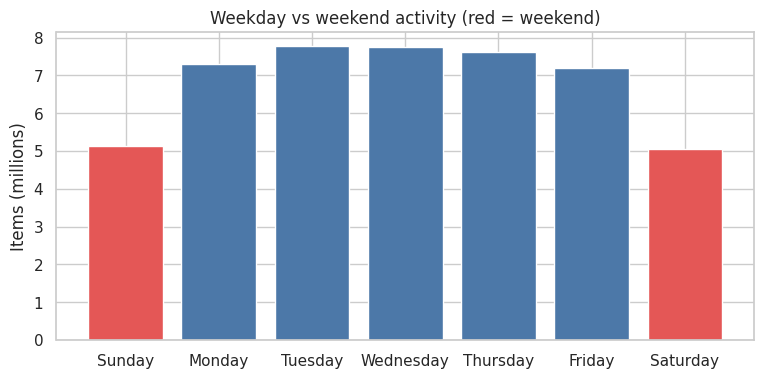

In [14]:
colors = ["#E45756" if d in ("Saturday", "Sunday") else "#4C78A8" for d in df_5["day_name"]]
plt.figure(figsize=(9, 4))
plt.bar(df_5["day_name"], df_5["total_posts"] / 1e6, color=colors)
plt.ylabel("Items (millions)")
plt.title("Weekday vs weekend activity (red = weekend)")
plt.show()

Business Question 5: Which day of the week has the highest activity?

Interpretation & Key Findings

Weekdays are busier than weekends: Monday to Friday account for about 79% of all items, and Saturday and Sunday for only about 21%. Each weekend day has about 5.1 million items, about 34% fewer than a Tuesday.

Little difference between weekdays: Tuesday (7.77 million) and Wednesday (7.76 million) are the busiest days and are almost identical. Monday, Thursday and Friday are all within about 7% of Tuesday, so there is no sharp midweek peak.

Quietest day: Saturday has the fewest items (5.05 million), slightly fewer than Sunday (5.13 million).

Interpretation: A strong weekday and weekend gap is consistent with Hacker News being used mostly during working days, but this data cannot show who the users are or why.

Note: Days are based on UTC timestamps, so activity late in the evening in the Americas is counted on the next UTC day. Counts exclude dead and deleted items.

In [15]:
# Business Question 6: During which hours are users most active?

query_6 = """
SELECT EXTRACT(HOUR FROM timestamp) AS hour_of_day,
       COUNT(*) AS total_posts
FROM `bigquery-public-data.hacker_news.full`
WHERE timestamp IS NOT NULL AND dead IS NOT TRUE AND deleted IS NOT TRUE
GROUP BY hour_of_day
ORDER BY hour_of_day
"""

df_6 = run(query_6)
df_6['pct_of_peak'] = (100 * df_6['total_posts'] / df_6['total_posts'].max()).round(1)
df_6

,hour_of_day,total_posts,pct_of_peak
0,0,1739270,56.4
1,1,1572427,51.0
2,2,1456799,47.2
3,3,1368003,44.4
4,4,1283077,41.6
5,5,1227837,39.8
6,6,1235159,40.1
7,7,1272088,41.3
8,8,1299356,42.1
9,9,1304606,42.3


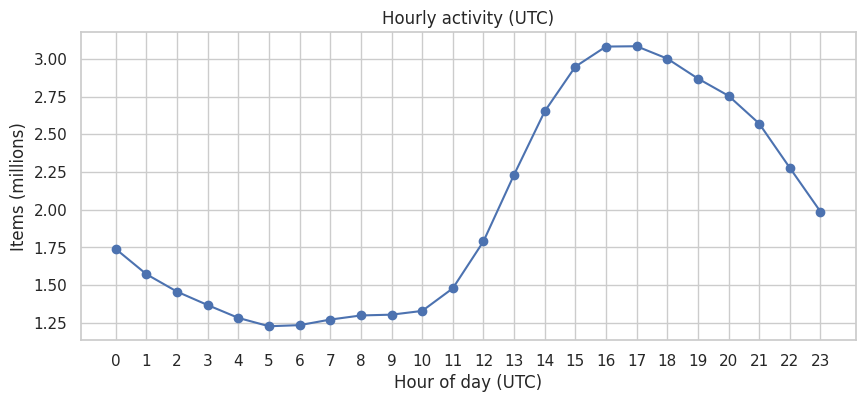

In [16]:
plt.figure(figsize=(10, 4))
plt.plot(df_6["hour_of_day"], df_6["total_posts"] / 1e6, marker="o")
plt.xticks(range(24))
plt.xlabel("Hour of day (UTC)")
plt.ylabel("Items (millions)")
plt.title("Hourly activity (UTC)")
plt.show()

Business Question 6: During which hours are users most active?

Interpretation & Key Findings

Afternoon peak: Activity is highest at 16:00 and 17:00 UTC, with about 3.08 million items in each hour. From 15:00 to 19:00 UTC every hour is above 93% of the peak. These five hours, about a fifth of the day, account for about 31% of all items.

Steep rise: Activity climbs quickly from 11:00 UTC (48% of the peak) to 15:00 UTC (96%), then falls gradually through the evening to about 65% of the peak at 23:00 UTC.

Quietest period: The lowest volume is at 05:00 UTC (1.23 million items, about 40% of the peak). From 04:00 to 10:00 UTC every hour stays between about 40% and 43% of the peak.

Interpretation: The site is never close to empty, since even the quietest hour has about 40% of peak activity, which is consistent with a worldwide audience. The afternoon peak in UTC is consistent with a large share of activity coming from the Americas and Europe working hours, but timestamps do not show where users are.

Note: Hours are in UTC. Counts exclude dead and deleted items.

In [17]:
# Business Question 7: How has the share of AI-related story titles changed over time?

query_7 = r"""
SELECT EXTRACT(YEAR FROM timestamp) AS year,
       COUNT(*) AS stories,
       COUNTIF(REGEXP_CONTAINS(title, r'(?i)\b(ai|llm|llms|gpt|chatgpt|openai)\b')) AS ai_stories
FROM `bigquery-public-data.hacker_news.full`
WHERE type = 'story' AND title IS NOT NULL
  AND dead IS NOT TRUE AND deleted IS NOT TRUE
GROUP BY year
ORDER BY year
"""

df_7 = run(query_7)
df_7['ai_share_pct'] = (100 * df_7['ai_stories'] / df_7['stories']).round(2)
df_7

,year,stories,ai_stories,ai_share_pct
0,2006,46,0,0.0
1,2007,21658,27,0.12
2,2008,61484,57,0.09
3,2009,87918,87,0.1
4,2010,140679,109,0.08
5,2011,199055,161,0.08
6,2012,232835,126,0.05
7,2013,260579,199,0.08
8,2014,247544,338,0.14
9,2015,262115,806,0.31


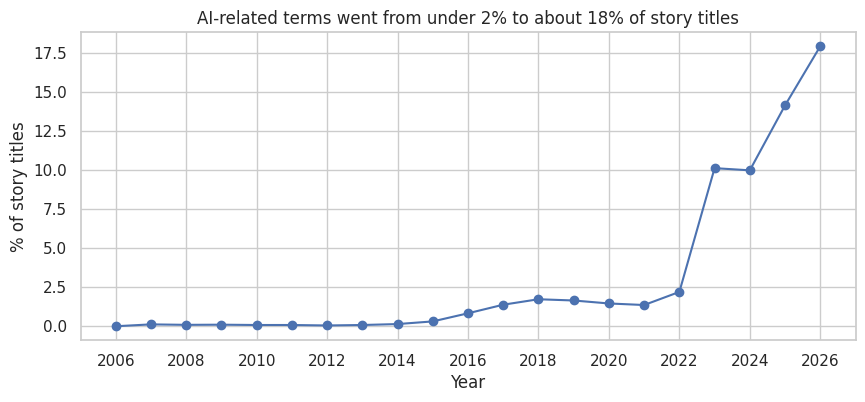

In [18]:
plt.figure(figsize=(10, 4))
plt.plot(df_7["year"], df_7["ai_share_pct"], marker="o")
plt.xticks(range(2006, 2027, 2))
plt.xlabel("Year")
plt.ylabel("% of story titles")
plt.title("AI-related terms went from under 2% to about 18% of story titles")
plt.show()

Business Question 7: How has the share of AI-related story titles changed over time?

Interpretation & Key Findings

Almost absent before 2015: From 2006 to 2014, AI-related terms appear in 0.14% of story titles or fewer.

Slow rise, then a jump: The share grew from 0.31% in 2015 to 1.73% in 2018, then drifted down to 1.36% by 2021 and rose to 2.2% in 2022. In 2023 it jumped to 10.13%, with 32,150 AI-related stories against 6,582 the year before, almost five times as many.

Still rising: The share was 9.99% in 2024, 14.15% in 2025 and 17.94% so far in 2026, about 13 times the 2021 level. The 2026 count (52,860 stories) already exceeds all of 2025 (42,715), even though the year is not over.

Interpretation: The timing is consistent with the surge of interest in large language models and generative AI from late 2022. This data shows when the change happened but cannot show why.

Note: The share is based on a keyword match on story titles (AI, LLM, LLMs, GPT, ChatGPT, OpenAI), which is a rough measure. It can match unrelated uses, such as a person named Ai, and miss AI-related titles that don’t use these words. 2026 is a partial year, shown as a share of stories so far. Counts exclude dead and deleted items.

## Key Findings Summary

Platform makeup: Hacker News is mainly a discussion site. Comments are about 87% of the 50.1 million items and stories about 13%.

Contributors: The most active account, dang (the site's moderator), has 81,070 items. Nine of the top 10 accounts mainly comment, and together the top 10 account for only about 1.2% of all items.

Scores: Story scores are very uneven. The median story scores 2 while the average is about 17, about 32% of stories score 1 or less, and the best story reached 6,015.

Growth and decline: Yearly activity grew to a peak of about 4.45 million items in 2023, fell 20% in 2024 and has since partly recovered. The monthly chart shows the fall was gradual, with a low of about 0.26 million items a month around the end of 2024.

Weekly and daily rhythm: Weekdays account for about 79% of items, and each weekend day has about 34% fewer items than a Tuesday. Activity peaks at 16:00 to 17:00 UTC, and even the quietest hour (05:00 UTC) has about 40% of peak activity.

AI topics: AI-related terms appeared in 0.14% or fewer of story titles up to 2014, reached 2.2% in 2022, jumped to 10.1% in 2023 and stand at 17.9% so far in 2026.

## Conclusion

This project used SQL on Google BigQuery to analyze 50.1 million Hacker News items from October 2006 to October 2026, using aggregation, window functions, approximate percentiles and regular expressions.

**What the data shows:** Hacker News is driven by discussion, and attention is very uneven. The typical story gets almost no votes (median score 2), while a small number of very popular stories pull the average up to about 17. No single account dominates the volume of activity, since the ten most active accounts make up only about 1.2% of all items. Usage follows a clear weekly and daily rhythm, with weekdays and the afternoon hours in UTC the busiest. Over time the site grew until 2023, declined through 2024 and has partly recovered, while the share of story titles about AI rose from 2.2% in 2022 to nearly 18% in 2026.

**Limitations:** Timestamps are in UTC and the data has no user locations, so it cannot show who the users are or why activity changed, including the 2024 decline. The AI share is based on a keyword match and is a rough measure. Comments have no scores, so the score analysis covers only stories and jobs. 2026 is a partial year and the data ends on 17 October 2026.

**Next steps:** Check whether the 2024 decline was concentrated in particular topics or user groups, compare the weekday and hourly patterns across years, and build a model that predicts which stories reach a high score, using a time-based train and test split.